# AutoSplice · CocoGlide 데이터 EDA

- 작성자: kimjaehak
- 상태: **완료 — Colab 저장 출력 검토 완료 (2026-11-17), T05 최종 확정은 별도 진행**
- 작성일: 2026-11-17
- 관련 작업: T05 데이터셋 EDA·분할 확정
- [보고서](../../docs/eda/EXP_kimjaehak_002_dataset_eda.md) · [기준 예제 보고서](../../docs/eda/EXP_kimjaehak_001_evaluation_example.md)

001에서 확인한 파일 로드 예제를 전체 데이터 점검으로 확장함. 이미지·마스크의 손상·값·크기, 원본 ID 분할, 정확히 같은 파일·RGB 픽셀의 중복을 확인함. AutoSplice 학습 데이터의 크기와 조작 영역 비율을 살펴 다음 학습 조건을 정할 근거를 마련함.

공통 분할 CSV를 그대로 읽으며 재분할하거나 파일을 수정·삭제하지 않음. 모델 학습·추론·성능 지표 계산은 하지 않음. AutoSplice test와 CocoGlide는 무결성·중복 검사에만 사용하며 학습 설정 선택용 그래프나 표본 선정에는 사용하지 않음.

팀원이 VS Code의 Colab 원격 커널에서 위에서부터 실행하고 출력이 포함된 노트북을 저장함. 에이전트는 저장된 결과로 보고서를 갱신함. 자동 검사가 끝나도 시각 정합성 검토와 분할 확정은 별도로 필요함.

## 1. Drive·공통 코드·실행 환경 준비

공유 Drive의 `AI_Forensics/datasets/AutoSplice/AutoSplice.zip`, `AI_Forensics/datasets/CocoGlide.zip`과 `AI_Forensics/project/scripts/`를 사용함. scripts에는 `__init__.py`, `datasets.py`, `preprocessing.py`, `splits/autosplice_seed42.csv`가 필요함.

새 커널에서 시작함. 누락 파일과 실제 import 위치를 확인해 다른 scripts 패키지를 잘못 불러오지 않도록 함. Drive 코드는 자동 동기화되지 않으므로 로컬과 같은 버전을 업로드해야 함. 코드·분할 해시가 이 초안을 작성한 버전과 다르면 중단함. 해시 불일치 시 현재 파일을 확인하고 실험 변경 내용을 기록해야 하며 기대 해시만 임의로 바꾸지 않음.

GPU는 사용하지 않음. 아래 버전은 실행 기록이며 팀 표준을 확정하는 셀이 아님.

In [7]:
from pathlib import Path
from google.colab import drive
import hashlib
import importlib
import importlib.metadata
import platform
import sys
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, features
from IPython.display import display

drive.mount("/content/drive")
shared_root = Path("/content/drive/MyDrive/AI_Forensics")
project_root = shared_root / "project"
work_root = Path("/content")
data_root = work_root / "datasets"
split_path = project_root / "scripts/splits/autosplice_seed42.csv"
archive_paths = {
    "AutoSplice": shared_root / "datasets/AutoSplice/AutoSplice.zip",
    "CocoGlide": shared_root / "datasets/CocoGlide.zip",
}
extract_paths = {"AutoSplice": data_root, "CocoGlide": data_root / "CocoGlide"}
required = ["scripts/__init__.py", "scripts/datasets.py", "scripts/preprocessing.py", "scripts/splits/autosplice_seed42.csv"]
for relative in required:
    if not (project_root / relative).is_file():
        raise FileNotFoundError(f"Drive에 공통 파일을 업로드해야 함: {relative}")

sys.path.insert(0, str(project_root))
importlib.invalidate_caches()
import scripts
import scripts.datasets as dataset_module
import scripts.preprocessing as preprocessing_module

for module, relative in [(scripts, "scripts/__init__.py"), (dataset_module, "scripts/datasets.py"),
                         (preprocessing_module, "scripts/preprocessing.py")]:
    if Path(module.__file__).resolve() != (project_root / relative).resolve():
        raise ImportError(f"프로젝트의 모듈을 불러오도록 커널을 재시작해야 함: {relative}")
    print("불러온 코드:", module.__file__)

from scripts.datasets import sha256, prepare_dataset_zip, autosplice_records, cocoglide_records
from scripts.preprocessing import load_rgb, load_binary_mask

print("실행 시각 UTC:", datetime.now(timezone.utc).isoformat())
print("Python:", platform.python_version())
print("OS:", platform.platform())
for package in ("numpy", "Pillow", "pandas", "matplotlib"):
    print(package, importlib.metadata.version(package))
print("JPEG library:", features.version("jpg"))
print("GPU: 사용하지 않음")
print("프로젝트:", project_root)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
불러온 코드: /content/drive/MyDrive/AI_Forensics/project/scripts/__init__.py
불러온 코드: /content/drive/MyDrive/AI_Forensics/project/scripts/datasets.py
불러온 코드: /content/drive/MyDrive/AI_Forensics/project/scripts/preprocessing.py
실행 시각 UTC: 2026-11-16T17:22:32.383147+00:00
Python: 3.13.16
OS: Linux-6.6.159+-x86_64-with-glibc2.39
numpy 2.4.6
Pillow 11.3.0
pandas 2.2.3
matplotlib 3.10.0
JPEG library: 6.2
GPU: 사용하지 않음
프로젝트: /content/drive/MyDrive/AI_Forensics/project


In [8]:
expected_files = {
    "scripts/__init__.py": "e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855",
    "scripts/datasets.py": "435215ef08c2c43ce2f84795d783895074eee85f8e062f28ea8ee6acabad3e88",
    "scripts/preprocessing.py": "69809276be12200a3cd2ef1e96364a7d168b39cae0a2cce1946f84d7ce74db07",
    "scripts/splits/autosplice_seed42.csv": "f8a2893ab93b82264e6434fa0c26f09472de05bd98829065c2a0db846ace7b1e"
}
for relative, expected_hash in expected_files.items():
    actual_hash = sha256(project_root / relative)
    print(relative, actual_hash)
    if actual_hash != expected_hash:
        raise ValueError(f"검토한 코드·분할 버전과 일치해야 함: {relative}")

mask_foreground = 255
preview_count = 6
crop_candidates = (128, 256, 384, 512)
print("분석 설정:", dict(mask_foreground=mask_foreground, preview_count=preview_count, crop_candidates=crop_candidates))
print("크롭 후보는 기하학적 가능성 비교용이며 학습 크기로 확정한 값이 아님")

scripts/__init__.py e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855
scripts/datasets.py 435215ef08c2c43ce2f84795d783895074eee85f8e062f28ea8ee6acabad3e88
scripts/preprocessing.py 69809276be12200a3cd2ef1e96364a7d168b39cae0a2cce1946f84d7ce74db07
scripts/splits/autosplice_seed42.csv f8a2893ab93b82264e6434fa0c26f09472de05bd98829065c2a0db846ace7b1e
분석 설정: {'mask_foreground': 255, 'preview_count': 6, 'crop_candidates': (128, 256, 384, 512)}
크롭 후보는 기하학적 가능성 비교용이며 학습 크기로 확정한 값이 아님


## 2. 데이터 ZIP 준비

001과 같은 ZIP·공통 함수를 사용함. AutoSplice는 ZIP 안에 AutoSplice 폴더가 있으므로 datasets에, CocoGlide는 datasets/CocoGlide에 해제함. 기존 완료 표시가 있으면 해제 파일을 재사용함. 해제 파일을 직접 수정·삭제했다면 완료 표시를 지우고 다시 준비해야 함.

첫 전체 점검은 새 Colab 런타임에서 ZIP을 새로 해제해 시작함. 커널만 재시작하면 /content의 기존 해제 파일은 남을 수 있음. 완료 표시 재사용은 해제 파일과 ZIP 내부 파일의 바이트 일치까지 보장하지 않음.

이후 검사는 전체 파일을 읽으므로 시간이 걸릴 수 있음. 검사 중에는 데이터나 공통 코드를 교체하지 않음.

In [9]:
archive_hashes = {
    "AutoSplice": "0d94e2df6842f44c11e21ee207707c49fd9717ec89048bd6f28fc1e07c4a5e36",
    "CocoGlide": "fc848643ad0a81010ba2a6ab8c055762782f54e4fb9e407210dbfe1c3b538af9",
}
for name, source in archive_paths.items():
    prepare_dataset_zip(source, work_root / f"{name}.zip", extract_paths[name], archive_hashes[name])
    print(name, "ZIP SHA-256:", archive_hashes[name])

AutoSplice 기존 해제 파일 사용
AutoSplice ZIP SHA-256: 0d94e2df6842f44c11e21ee207707c49fd9717ec89048bd6f28fc1e07c4a5e36
CocoGlide 기존 해제 파일 사용
CocoGlide ZIP SHA-256: fc848643ad0a81010ba2a6ab8c055762782f54e4fb9e407210dbfe1c3b538af9


## 3. 고정 분할·품질별 연결·전체 파일 목록

같은 AutoSplice 원본의 정상·조작본·JPEG 품질 변형이 하나의 split에 속하는지 확인함. 다른 데이터셋의 숫자 ID가 같다고 같은 원본으로 취급하지 않음.

AutoSplice 정상 파일은 품질별 목록에 반복되므로 한 번만 등록함. 하나의 마스크를 여러 조작본이 공유하는 것은 허용하고 고유 마스크 수를 별도로 셈. CocoGlide는 CSV의 real·fake·mask 경로 중복도 확인함. 알려진 개수는 기존 ZIP 점검 기록과 대조하는 값이며 새 실행의 결과를 미리 채운 것이 아님.

In [10]:
auto_by_quality = {q: autosplice_records(data_root / "AutoSplice", split_path, q) for q in (100, 90, 75)}
coco_records = cocoglide_records(data_root / "CocoGlide")
split_table = pd.read_csv(split_path, dtype=str)
if split_table["original_id"].duplicated().any() or split_table.isna().any().any():
    raise ValueError("분할 CSV에 누락이나 중복 ID가 없어야 함.")
if split_table.groupby("split").size().to_dict() != {"train": 1818, "val": 227, "test": 228}:
    raise ValueError("확인한 원본 ID 분할 수와 일치해야 함.")

signature = None
records = []
for quality, rows in auto_by_quality.items():
    forged = [row for row in rows if row["kind"] == "manipulated"]
    current = {(row["image_path"].name, row["original_id"], row["split"], row["mask_path"].name) for row in forged}
    if len(forged) != 3621 or (signature is not None and current != signature):
        raise ValueError("AutoSplice 세 품질의 조작본·원본 ID·마스크·분할 연결이 같아야 함.")
    signature = current
    for row in rows:
        if row["kind"] == "normal" and quality != 100:
            continue
        records.append(dict(row, quality=str(quality) if row["kind"] == "manipulated" else "original"))
records.extend(dict(row, quality="PNG") for row in coco_records)
manifest = pd.DataFrame(records)
if manifest["image_path"].duplicated().any():
    raise ValueError("파일 목록의 이미지 경로는 중복되지 않아야 함.")
if manifest.groupby(["dataset", "original_id"])["split"].nunique().max() != 1:
    raise ValueError("같은 데이터셋·원본 ID는 하나의 분할에만 속해야 함.")

coco_table = pd.read_csv(data_root / "CocoGlide/table.csv", dtype=str)
if len(coco_table) != 512 or coco_table[["real", "fake", "mask"]].isna().any().any():
    raise ValueError("CocoGlide의 연결 512개에 누락 경로가 없어야 함.")
for column in ("real", "fake", "mask"):
    if coco_table[column].duplicated().any():
        raise ValueError(f"CocoGlide CSV의 경로 중복을 검토해야 함: {column}")

display(manifest.groupby(["dataset", "split", "kind", "quality"]).size().rename("files").to_frame())
display(manifest.dropna(subset=["mask_path"]).groupby("dataset")["mask_path"].nunique().rename("unique_masks").to_frame())
print("원본 ID의 분할 격리와 세 JPEG 품질의 연결 확인 완료")

files
dataset    split         kind        quality        
AutoSplice test          manipulated 100         335
                                     75          335
                                     90          335
                         normal      original    228
           train         manipulated 100        2925
                                     75         2925
                                     90         2925
                         normal      original   1818
           val           manipulated 100         361
                                     75          361
                                     90          361
                         normal      original    227
CocoGlide  external_test manipulated PNG         512
                         normal      PNG         512

,unique_masks
dataset,
AutoSplice,1710
CocoGlide,512


원본 ID의 분할 격리와 세 JPEG 품질의 연결 확인 완료


In [11]:
image_suffixes = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
folders = [data_root / "AutoSplice" / folder for folder in ("Authentic", "Forged_JPEG100", "Forged_JPEG90", "Forged_JPEG75")]
folders += [data_root / "CocoGlide" / folder for folder in ("real", "fake")]
mask_folders = [data_root / "AutoSplice/Mask", data_root / "CocoGlide/mask"]
image_paths = {path for folder in folders for path in folder.rglob("*") if path.is_file() and path.suffix.lower() in image_suffixes}
mask_paths = {path for folder in mask_folders for path in folder.rglob("*") if path.is_file() and path.suffix.lower() in image_suffixes}
referenced_images = set(manifest["image_path"])
referenced_masks = set(manifest["mask_path"].dropna())
inventory_rows = []
for kind, actual, referenced in [("image", image_paths, referenced_images), ("mask", mask_paths, referenced_masks)]:
    for path in sorted(referenced - actual):
        inventory_rows.append(dict(kind=kind, issue="missing", path=str(path)))
    for path in sorted(actual - referenced):
        inventory_rows.append(dict(kind=kind, issue="unreferenced", path=str(path)))
inventory_issues = pd.DataFrame(inventory_rows, columns=["kind", "issue", "path"])
print("고유 이미지:", len(image_paths), "고유 마스크:", len(mask_paths))
print("목록 차이:", len(inventory_issues))
if not inventory_issues.empty:
    print(inventory_issues.to_string(index=False))
if (inventory_issues["issue"] == "missing").any():
    raise ValueError("목록에 연결된 모든 이미지·마스크 파일이 있어야 함.")
print("미참조 파일은 삭제하지 않고 검토 대상으로 남김")

고유 이미지: 14160 고유 마스크: 2222
목록 차이: 0
미참조 파일은 삭제하지 않고 검토 대상으로 남김


## 4. 이미지·마스크 전수 읽기

헤더만 확인하지 않고 실제 픽셀을 끝까지 디코드함. 고유 경로별로 검사하고 배열은 모아두지 않음. 마스크는 원본 값 검사 후 공통 로더로 다시 읽어 변환을 확인함. 마스크는 원본 모드·값과 전경 픽셀 수를 기록하고 공통 로더로 0/1 변환도 확인함.

이미지의 파일 SHA-256과 디코드 RGB SHA-256을 함께 기록함. RGB 해시에는 높이·너비·채널·자료형도 포함함. 오류는 파일별로 모아 출력하고, 오류가 있으면 다음 분포 분석 전에 중단함. EXIF 방향이 1이 아닌 경우와 예상하지 않은 모드는 자동 변환하지 않고 검토 대상으로 표시함.

In [12]:
def inspect_file(path, is_mask):
    with Image.open(path) as image:
        image.load()
        width, height = image.size
        info = dict(path=path, width=width, height=height, mode=image.mode,
                    orientation=image.getexif().get(274, 1), file_sha256=sha256(path))
        if is_mask:
            raw = np.array(image)
            values = np.unique(raw).tolist()
            if raw.ndim != 2 or raw.size == 0 or not np.isin(raw, (0, mask_foreground)).all():
                raise ValueError("마스크는 0과 지정한 전경값만 가진 2차원 배열이어야 함.")
            mask = load_binary_mask(path, foreground_value=mask_foreground)
            info.update(values=str(values), foreground_pixels=int(mask.sum()), area_ratio=float(mask.mean()))
        else:
            rgb = np.array(image.convert("RGB"), dtype=np.uint8)
            digest = hashlib.sha256(f"{rgb.shape}|{rgb.dtype}".encode())
            digest.update(rgb.tobytes())
            info["rgb_sha256"] = digest.hexdigest()
    return info

image_info, mask_info, errors = {}, {}, []
for kind, paths, target in [("image", image_paths, image_info), ("mask", mask_paths, mask_info)]:
    for index, path in enumerate(sorted(paths), 1):
        try:
            target[path] = inspect_file(path, is_mask=(kind == "mask"))
        except Exception as error:
            errors.append(dict(kind=kind, path=str(path), error=f"{type(error).__name__}: {error}"))
        if index % 500 == 0 or index == len(paths):
            print(kind, index, "/", len(paths), "검사함")

for row in records:
    image_data = image_info.get(row["image_path"])
    real_data = image_info.get(row["real_path"])
    if image_data is None or real_data is None:
        continue
    size = (image_data["height"], image_data["width"])
    if size != (real_data["height"], real_data["width"]):
        errors.append(dict(kind="pair", path=str(row["image_path"]), error="원본·조작본 크기가 다름"))
    if row["mask_path"] is not None and row["mask_path"] in mask_info:
        info = mask_info[row["mask_path"]]
        if size != (info["height"], info["width"]):
            errors.append(dict(kind="pair", path=str(row["image_path"]), error="조작본·마스크 크기가 다름"))

error_table = pd.DataFrame(errors, columns=["kind", "path", "error"])
print("읽기·값·크기 오류:", len(error_table))
if not error_table.empty:
    print(error_table.to_string(index=False))
    raise ValueError("오류 파일을 확인한 뒤 분석을 계속해야 함.")
images = pd.DataFrame(image_info.values())
masks = pd.DataFrame(mask_info.values())
if images.empty or masks.empty:
    raise ValueError("검사할 이미지와 마스크가 있어야 함.")
display(images.groupby(["mode", "orientation"]).size().rename("image_files").to_frame())
display(masks.groupby(["mode", "values", "orientation"]).size().rename("mask_files").to_frame())
orientation_issues = pd.concat([images.loc[images["orientation"] != 1], masks.loc[masks["orientation"] != 1]])
mode_issues = pd.concat([images.loc[images["mode"] != "RGB"], masks.loc[masks["mode"] != "L"]])
mask_extremes = masks.loc[masks["area_ratio"].isin([0.0, 1.0])]
for title, table in [("EXIF 방향 검토", orientation_issues), ("모드 검토", mode_issues), ("빈·전체 전경 마스크 검토", mask_extremes)]:
    print(title, len(table))
    if not table.empty:
        print(table[["path", "mode", "orientation"]].to_string(index=False))
if not mask_extremes.empty:
    print(mask_extremes[["path", "foreground_pixels", "area_ratio"]].to_string(index=False))
print("전체 파일 읽기·마스크 값·대응 크기 자동 검사 완료")

image 500 / 14160 검사함
image 1000 / 14160 검사함
image 1500 / 14160 검사함
image 2000 / 14160 검사함
image 2500 / 14160 검사함
image 3000 / 14160 검사함
image 3500 / 14160 검사함
image 4000 / 14160 검사함
image 4500 / 14160 검사함
image 5000 / 14160 검사함
image 5500 / 14160 검사함
image 6000 / 14160 검사함
image 6500 / 14160 검사함
image 7000 / 14160 검사함
image 7500 / 14160 검사함
image 8000 / 14160 검사함
image 8500 / 14160 검사함
image 9000 / 14160 검사함
image 9500 / 14160 검사함
image 10000 / 14160 검사함
image 10500 / 14160 검사함
image 11000 / 14160 검사함
image 11500 / 14160 검사함
image 12000 / 14160 검사함
image 12500 / 14160 검사함
image 13000 / 14160 검사함
image 13500 / 14160 검사함
image 14000 / 14160 검사함
image 14160 / 14160 검사함
mask 500 / 2222 검사함
mask 1000 / 2222 검사함
mask 1500 / 2222 검사함
mask 2000 / 2222 검사함
mask 2222 / 2222 검사함
읽기·값·크기 오류: 0


,,image_files
mode,orientation,
RGB,1,14160


,,,mask_files
mode,values,orientation,
L,"[0, 255]",1,2222


EXIF 방향 검토 0
모드 검토 0
빈·전체 전경 마스크 검토 0
전체 파일 읽기·마스크 값·대응 크기 자동 검사 완료


## 5. 정확히 같은 이미지의 중복 확인

연결 목록에 등록된 이미지에서 파일 바이트가 같은 경우와, 파일 형식·메타데이터가 달라도 디코드 RGB가 같은 경우를 각각 검사함. 마스크 모양이 같다는 이유로 이미지 누수라고 판단하지 않으므로 마스크 해시는 누수 검사에 사용하지 않음.

같은 원본·같은 split의 JPEG 변형은 예상 관계로 분류함. 다른 split·데이터셋에 걸친 그룹은 누수 후보임. 같은 split에서도 다른 원본 ID나 서로 다른 정상/조작 라벨·마스크가 연결된 중복은 검토 대상으로 남김. 파일을 삭제하거나 분할을 자동 수정하지 않음. 미참조 파일은 분할·라벨 연결이 없어 이 중복 집계에서 제외하며 3절의 목록 차이로 별도 검토함.

이 검사는 재압축·리사이즈·크롭된 근접 중복을 모두 찾지 못함. 후보가 0개여도 '모든 데이터 누수가 없음'으로 결론내리지 않음.

In [13]:
image_table = manifest.merge(images, left_on="image_path", right_on="path", how="left", validate="one_to_one")

def duplicate_groups(frame, hash_column):
    rows = []
    duplicated = frame.loc[frame[hash_column].duplicated(keep=False)]
    for digest, group in duplicated.groupby(hash_column, sort=True):
        split_crossing = group[["dataset", "split"]].drop_duplicates().shape[0] > 1
        different_origin = group[["dataset", "original_id"]].drop_duplicates().shape[0] > 1
        label_conflict = group["kind"].nunique() > 1
        different_mask = group["mask_path"].dropna().nunique() > 1
        review = split_crossing or different_origin or label_conflict or different_mask
        rows.append(dict(hash=digest, files=len(group), split_crossing=split_crossing, review=review,
                         different_origin=different_origin, label_conflict=label_conflict, different_mask=different_mask,
                         members="; ".join(f"{r.dataset}/{r.split}/{r.original_id}/{r.kind}: {r.image_path.relative_to(data_root)}" for r in group.itertuples())))
    return pd.DataFrame(rows, columns=["hash", "files", "split_crossing", "review", "different_origin", "label_conflict", "different_mask", "members"])

duplicate_results = {}
for column in ("file_sha256", "rgb_sha256"):
    groups = duplicate_groups(image_table, column)
    duplicate_results[column] = groups
    print(column, "전체 중복 그룹:", len(groups), "분할·데이터셋 교차 그룹:", int(groups["split_crossing"].sum()))
    review_groups = groups.loc[groups["review"] == True]
    print("검토할 중복 그룹:", len(review_groups))
    if not review_groups.empty:
        print(review_groups.to_string(index=False))
    print("같은 원본·분할·라벨·마스크의 품질 변형 그룹:", len(groups) - len(review_groups))

file_sha256 전체 중복 그룹: 0 분할·데이터셋 교차 그룹: 0
검토할 중복 그룹: 0
같은 원본·분할·라벨·마스크의 품질 변형 그룹: 0
rgb_sha256 전체 중복 그룹: 0 분할·데이터셋 교차 그룹: 0
검토할 중복 그룹: 0
같은 원본·분할·라벨·마스크의 품질 변형 그룹: 0


## 6. AutoSplice 학습 데이터의 크기·조작 영역 분포

크기와 크롭 가능성은 train의 정상 원본과 JPEG100 조작본을 구분해 집계함. JPEG90·75는 같은 조작본을 반복 세지 않도록 제외함. 조작 영역 비율은 JPEG100 조작 파일 단위와 고유 마스크 단위를 따로 보여줌. 원본당 조작본이 많으면 파일 단위 통계에서 더 큰 비중을 차지함.

크롭 후보는 128·256·384·512 정사각형이며 모두 16의 배수임. 가능 비율은 이미지의 두 변이 후보 크기 이상인지만 확인함. 학습 크기 결정, 조작 영역 포함 확률, 배경만 나오는 크롭의 처리까지 해결한 결과는 아님. 테스트 데이터의 분포를 보고 이 후보나 학습 설정을 선택하지 않음.

height                                                        \
              count     mean      std    min    10%    50%    90%     max   
kind                                                                        
manipulated  2925.0  296.698  200.000  256.0  256.0  256.0  365.0  3744.0   
normal       1818.0  293.614  181.517  256.0  256.0  256.0  368.0  4232.0   

              width           ... short_side         aspect_ratio         \
              count     mean  ...        90%     max        count   mean   
kind                          ...                                          
manipulated  2925.0  363.761  ...      256.0  3744.0       2925.0  1.287   
normal       1818.0  360.941  ...      256.0  4232.0       1818.0  1.290   

                                                       
               std    min    10%    50%    90%    max  
kind                                                   
manipulated  0.352  0.521  0.721  1.465  1.586  2.711  
normal       0.359  0.521  0.715  1.459  1.617  2.891  

[2 rows x 32 columns]

,kind,crop_size,possible,total,fraction
0,manipulated,128,2925,2925,1.0000
1,manipulated,256,2925,2925,1.0000
2,manipulated,384,38,2925,0.0130
3,manipulated,512,37,2925,0.0126
4,normal,128,1818,1818,1.0000
5,normal,256,1818,1818,1.0000
6,normal,384,20,1818,0.0110
7,normal,512,18,1818,0.0099


,forged_files,unique_masks
count,2925.000000,1381.000000
mean,0.411073,0.407946
std,0.235210,0.231492
min,0.010638,0.010638
10%,0.073944,0.074710
50%,0.442393,0.440019
90%,0.697087,0.688924
max,0.980366,0.980366


train JPEG100 조작 파일: 2925 고유 마스크: 1381


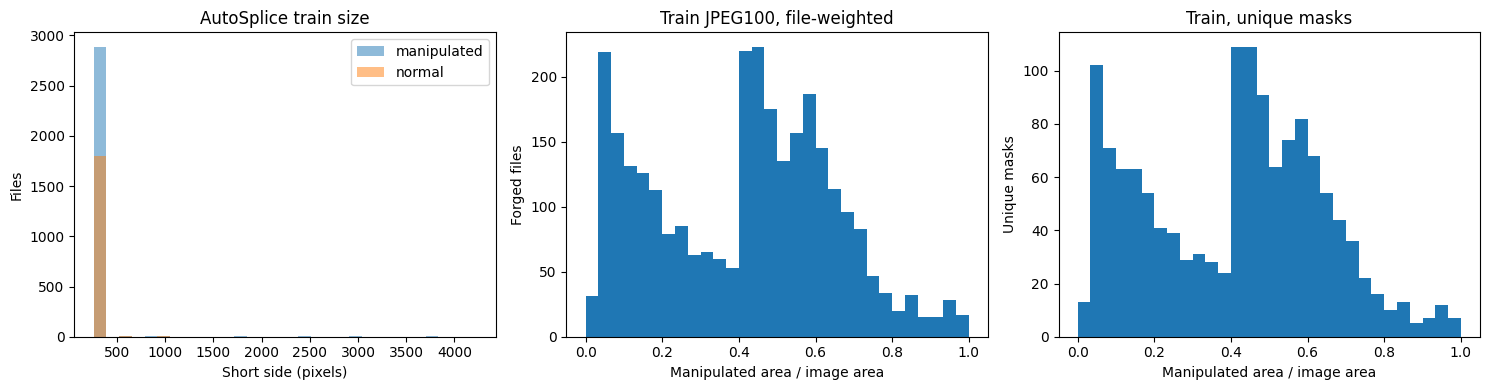

In [14]:
train = image_table.loc[(image_table["dataset"] == "AutoSplice") & (image_table["split"] == "train")
                        & image_table["quality"].isin(["original", "100"])].copy()
train["short_side"] = train[["height", "width"]].min(axis=1)
train["aspect_ratio"] = train["width"] / train["height"]
display(train.groupby("kind")[["height", "width", "short_side", "aspect_ratio"]].describe(percentiles=[0.1, 0.5, 0.9]).round(3))

crop_rows = []
for kind, group in train.groupby("kind"):
    for size in crop_candidates:
        possible = (group["height"] >= size) & (group["width"] >= size)
        crop_rows.append(dict(kind=kind, crop_size=size, possible=int(possible.sum()), total=len(group), fraction=float(possible.mean())))
crop_table = pd.DataFrame(crop_rows)
display(crop_table.round(4))

forged_train = train.loc[train["kind"] == "manipulated"].copy()
forged_train["area_ratio"] = forged_train["mask_path"].map(lambda path: mask_info[path]["area_ratio"])
unique_train_masks = forged_train.drop_duplicates("mask_path")
display(pd.DataFrame({"forged_files": forged_train["area_ratio"].describe(percentiles=[0.1, 0.5, 0.9]),
                      "unique_masks": unique_train_masks["area_ratio"].describe(percentiles=[0.1, 0.5, 0.9])}).round(6))
print("train JPEG100 조작 파일:", len(forged_train), "고유 마스크:", len(unique_train_masks))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
size_bins = np.histogram_bin_edges(train["short_side"], bins=30)
for kind, group in train.groupby("kind"):
    axes[0].hist(group["short_side"], bins=size_bins, alpha=0.5, label=kind)
axes[0].set(xlabel="Short side (pixels)", ylabel="Files", title="AutoSplice train size")
axes[0].legend()
axes[1].hist(forged_train["area_ratio"], bins=30, range=(0, 1))
axes[1].set(xlabel="Manipulated area / image area", ylabel="Forged files", title="Train JPEG100, file-weighted")
axes[2].hist(unique_train_masks["area_ratio"], bins=30, range=(0, 1))
axes[2].set(xlabel="Manipulated area / image area", ylabel="Unique masks", title="Train, unique masks")
plt.tight_layout()
plt.show()

## 7. 학습 표본의 마스크 정합성 보기

AutoSplice train JPEG100에서 고유 마스크별 첫 파일을 선택하고 조작 영역 비율 순으로 정렬함. 작은 영역부터 큰 영역까지 같은 간격의 순위에서 최대 6개를 뽑음. 결과를 보고 좋은 사례만 골라 바꾸지 않음. 작은 원본도 별도로 최대 3개 확인함.

원본 → 조작본 → 정답 마스크 → 조작본에 빨간 마스크를 겹친 그림을 보여줌. 물체가 바뀐 위치와 마스크가 대응하는지 사람이 확인해야 함. 크기·값 검사만으로는 마스크 의미가 맞는지 알 수 없음. 이 표본 확인으로 전체 데이터의 정합성을 보장하지 않음.

CocoGlide는 이 노트북에서 새 설정 선택용 시각화를 만들지 않음. 001에 저장된 한 쌍의 로드 예제를 참고하고, 추가 정합성 검토가 필요하면 테스트 성능 튜닝과 구분해 진행함.

조작 영역 비율 순위로 선택한 학습 표본


,original_id,image_path,height,width,area_ratio
5819,72394,/content/datasets/AutoSplice/Forged_JPEG100/72...,256,383,0.010638
2659,41777,/content/datasets/AutoSplice/Forged_JPEG100/41...,256,283,0.144724
4898,59865,/content/datasets/AutoSplice/Forged_JPEG100/59...,256,385,0.390310
3297,46402,/content/datasets/AutoSplice/Forged_JPEG100/46...,320,256,0.485742
3289,46354,/content/datasets/AutoSplice/Forged_JPEG100/46...,331,256,0.607215
4838,59348,/content/datasets/AutoSplice/Forged_JPEG100/59...,256,341,0.980366


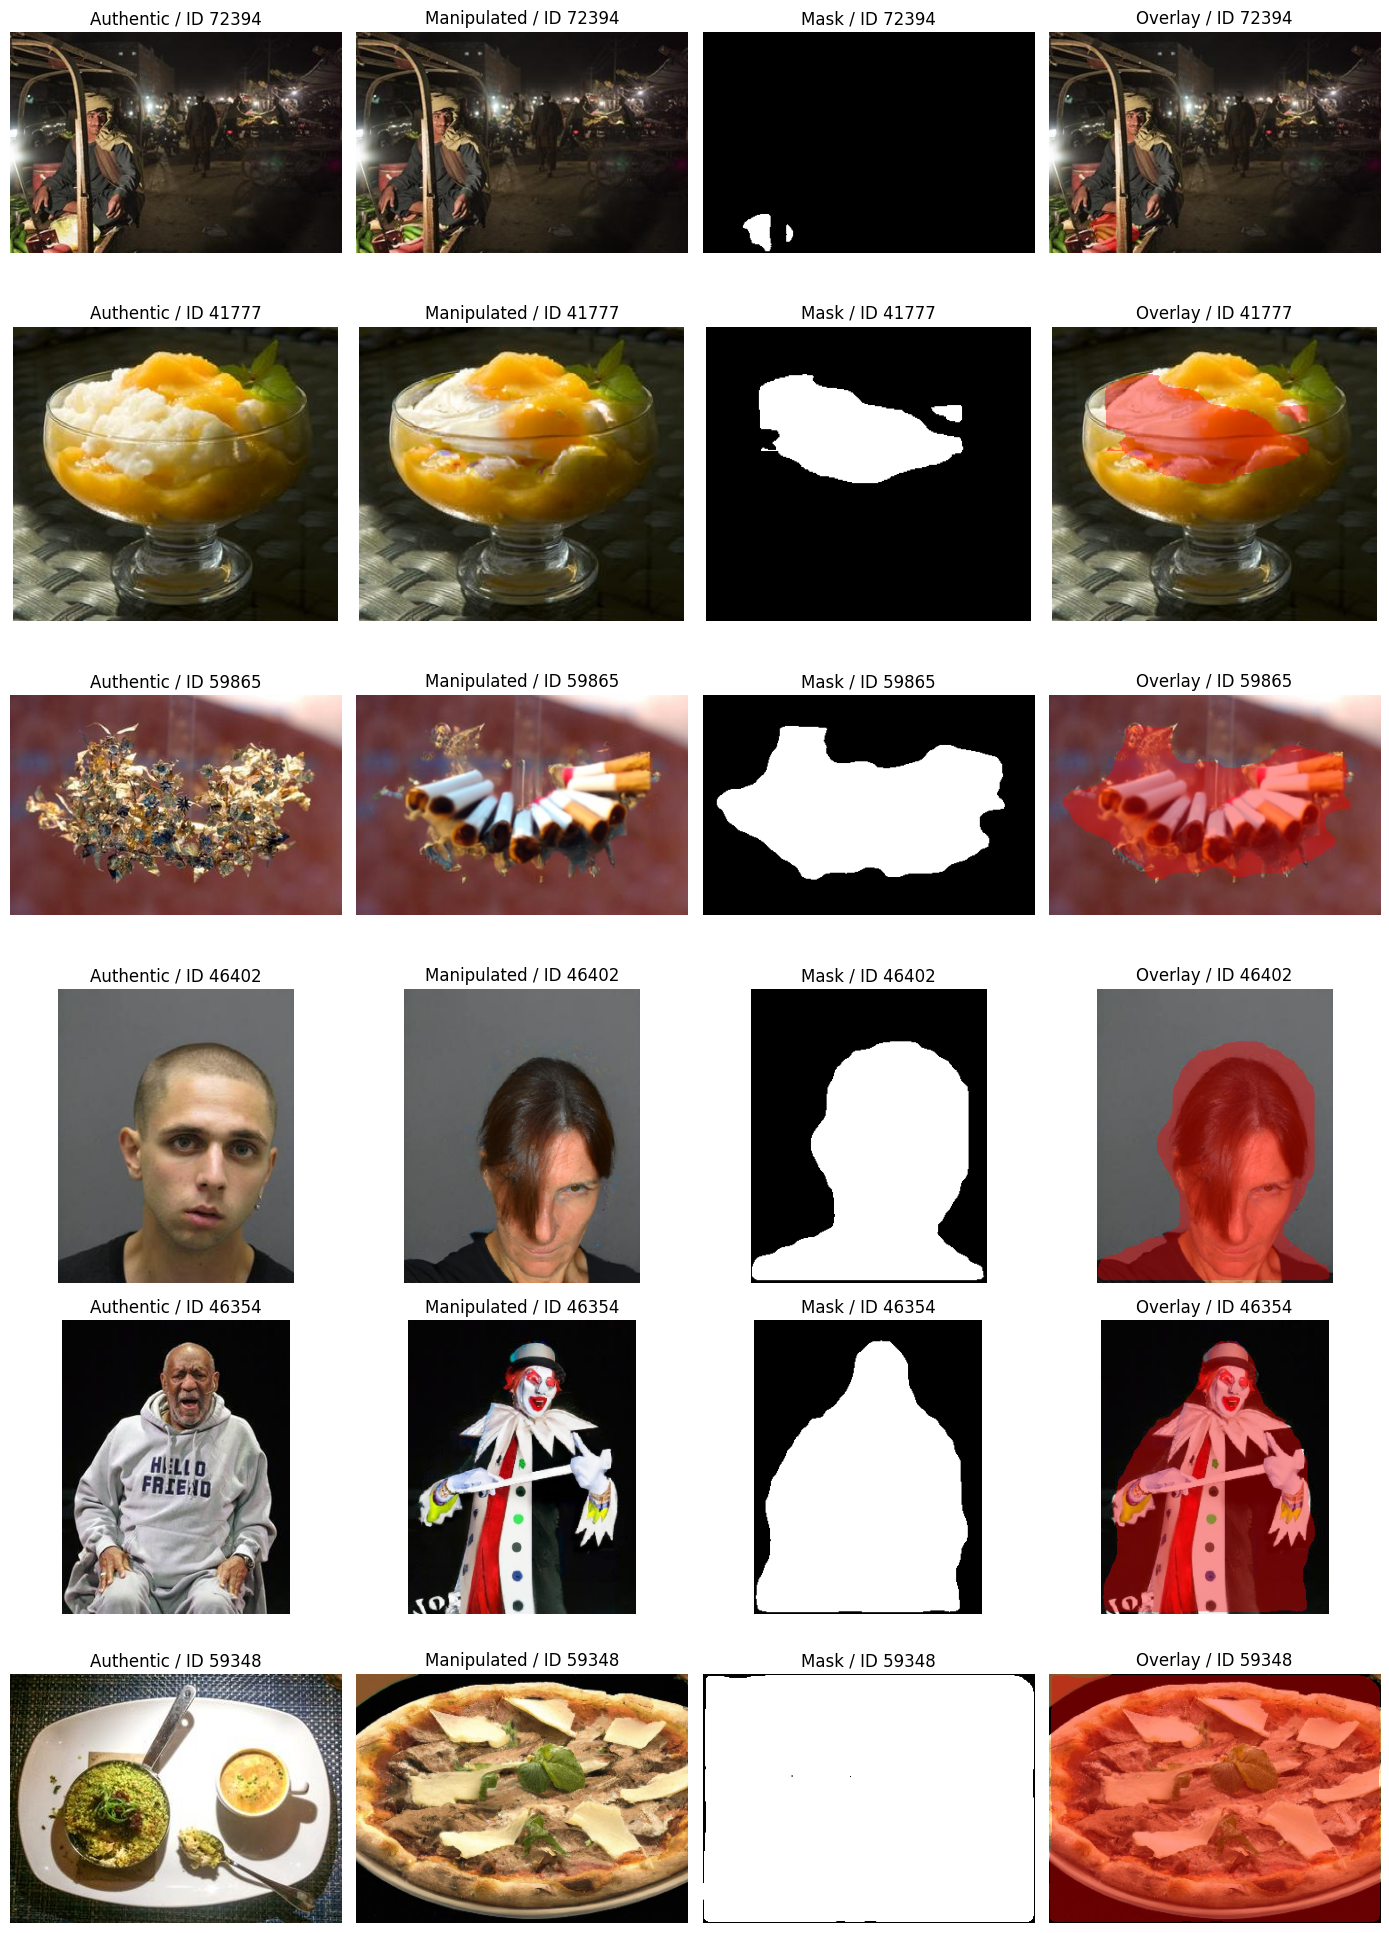

짧은 변이 작은 학습 원본 3개 이하


,original_id,image_path,height,width,area_ratio
2273,39406,/content/datasets/AutoSplice/Forged_JPEG100/39...,256,374,0.084820
2276,39436,/content/datasets/AutoSplice/Forged_JPEG100/39...,256,384,0.104808
2281,39457,/content/datasets/AutoSplice/Forged_JPEG100/39...,269,256,0.593242


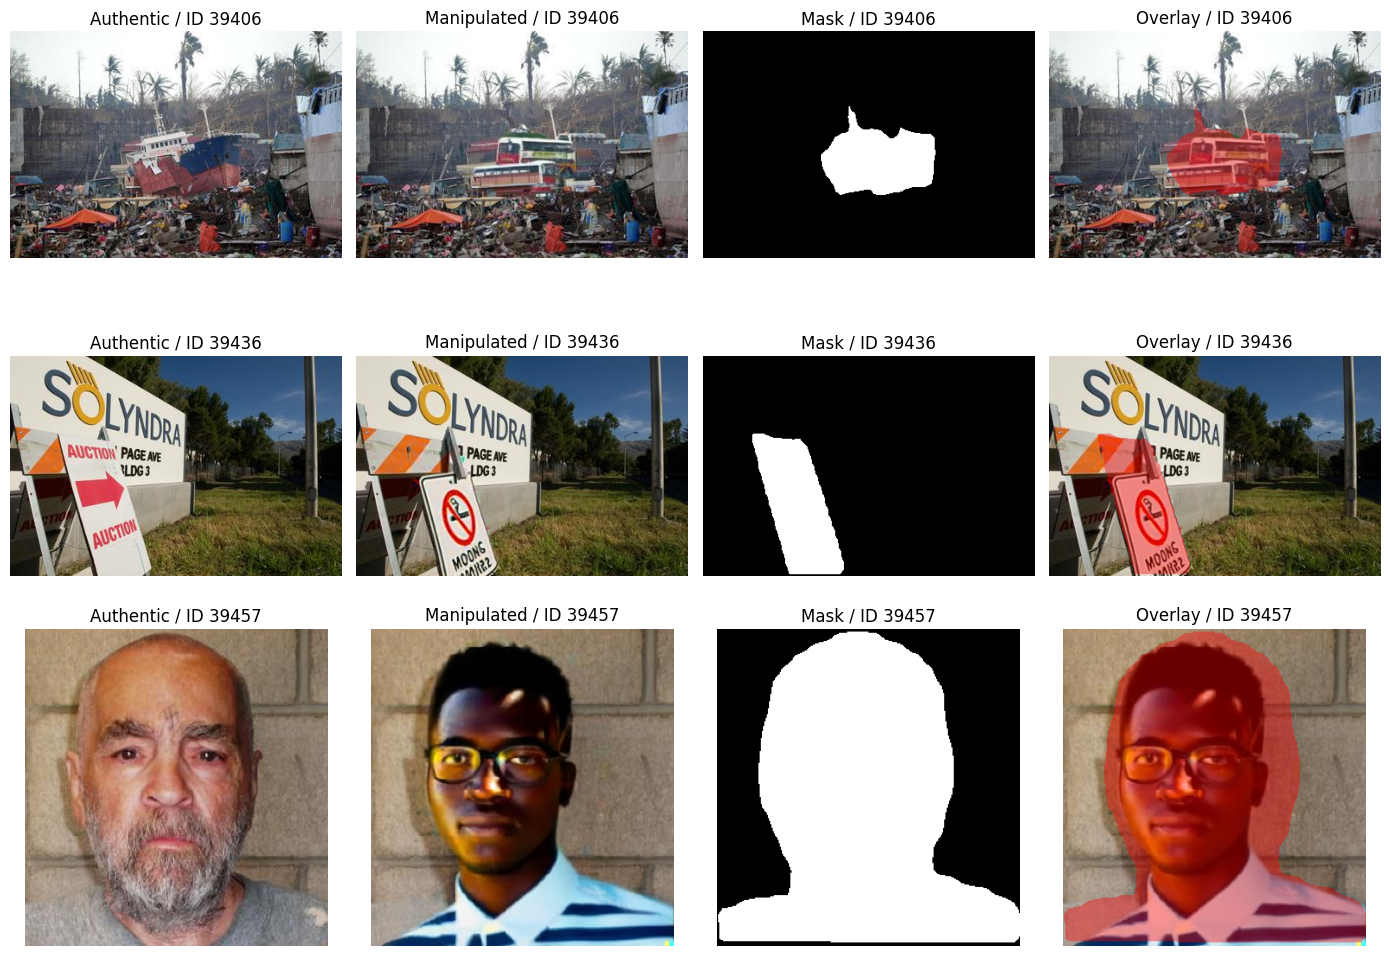

In [15]:
def show_pairs(selected):
    if selected.empty:
        print("표시할 학습 표본이 없음")
        return
    fig, axes = plt.subplots(len(selected), 4, figsize=(14, 3.3 * len(selected)), squeeze=False)
    for axes_row, row in zip(axes, selected.itertuples()):
        real = load_rgb(row.real_path)
        forged = load_rgb(row.image_path)
        mask = load_binary_mask(row.mask_path, foreground_value=mask_foreground)
        overlay = forged.astype(np.float32) / 255
        overlay[mask == 1] = 0.6 * overlay[mask == 1] + 0.4 * np.array([1.0, 0.0, 0.0])
        for ax, value, title in zip(axes_row, (real, forged, mask, overlay), ("Authentic", "Manipulated", "Mask", "Overlay")):
            if title == "Mask":
                ax.imshow(value, cmap="gray", vmin=0, vmax=1)
            else:
                ax.imshow(value)
            ax.set_title(f"{title} / ID {row.original_id}")
            ax.axis("off")
    plt.tight_layout()
    plt.show()

ordered = forged_train.sort_values(["area_ratio", "original_id", "image_path"]).drop_duplicates("mask_path")
positions = np.linspace(0, len(ordered) - 1, min(preview_count, len(ordered))).astype(int)
selected = ordered.iloc[positions]
print("조작 영역 비율 순위로 선택한 학습 표본")
display(selected[["original_id", "image_path", "height", "width", "area_ratio"]])
show_pairs(selected)
smallest = forged_train.sort_values(["short_side", "original_id", "image_path"]).drop_duplicates("original_id").head(3)
print("짧은 변이 작은 학습 원본 3개 이하")
display(smallest[["original_id", "image_path", "height", "width", "area_ratio"]])
show_pairs(smallest)

## 8. 결과 정리와 T05 완료 판단

아래 표는 자동 검사에서 남은 검토 항목을 요약함. 동일 중복이 발견되면 관련 원본을 같은 그룹으로 묶을 필요가 있는지 판단해야 하며 CSV를 자동으로 다시 만들지 않음. 분할 변경이 필요하면 근거·영향·새 파일 버전을 별도로 합의함.

T05 완료에는 저장된 자동 검사 결과, 사람이 확인한 마스크 정합성, 정확한 중복 및 근접 중복 검토 범위의 기록이 필요함. 후보가 없는 것이 근접 중복 검사 완료를 뜻하지 않음. 팀원은 그림에서 발견한 의심 사례의 ID와 이유를 아래 검토 메모에 남기고 출력이 포함된 파일을 저장함. 보고서에는 실제 출력에서 확인한 값만 반영함.

In [16]:
review_summary = pd.DataFrame([
    dict(item="파일 읽기·마스크 값·대응 크기 오류", count=len(error_table)),
    dict(item="목록과 실제 폴더 차이", count=len(inventory_issues)),
    dict(item="EXIF 방향 검토 파일", count=len(orientation_issues)),
    dict(item="원본 모드 검토 파일", count=len(mode_issues)),
    dict(item="빈·전체 전경 마스크", count=len(mask_extremes)),
    dict(item="파일 해시 기준 검토 중복 그룹", count=int(duplicate_results["file_sha256"]["review"].sum())),
    dict(item="RGB 해시 기준 검토 중복 그룹", count=int(duplicate_results["rgb_sha256"]["review"].sum())),
])
display(review_summary)
print("자동 검사와 학습 데이터 분포 출력까지 완료함. T05 최종 확정은 저장 출력·시각 검토 후 진행해야 함.")
print("근접 중복 검사: 미실행 / 모델 성능: 해당 없음 / 기존 분할 CSV: 변경 없음")

,item,count
0,파일 읽기·마스크 값·대응 크기 오류,0
1,목록과 실제 폴더 차이,0
2,EXIF 방향 검토 파일,0
3,원본 모드 검토 파일,0
4,빈·전체 전경 마스크,0
5,파일 해시 기준 검토 중복 그룹,0
6,RGB 해시 기준 검토 중복 그룹,0


자동 검사와 학습 데이터 분포 출력까지 완료함. T05 최종 확정은 저장 출력·시각 검토 후 진행해야 함.
근접 중복 검사: 미실행 / 모델 성능: 해당 없음 / 기존 분할 CSV: 변경 없음


### 사람의 검토 메모

- 마스크 정합성 확인: 미확인
- 의심 사례 ID·파일명·이유: 미기록
- 미참조 파일·EXIF·모드·중복 후보에 대한 판단: 미확인
- 크롭 크기 등 학습 설정 결정: 미정, T06에서 논의함
- 근접 중복 추가 검사 범위: 미정
- T05 완료 여부: 결과 검토 전

[개별 보고서](../../docs/eda/EXP_kimjaehak_002_dataset_eda.md) · [EDA 목록](../../docs/results.md) · [TODO](../../TODO.md)